# Homework 6 - 2c

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

Mean-flow orbit results
x range: 0.162783 to 0.808186
y range: 0.191814 to 0.837217
K initial: 1.4338318235
K final:   1.4338318235
K minimum: 1.4338318235
K maximum: 1.4338318235
K variation: 3.508e-14


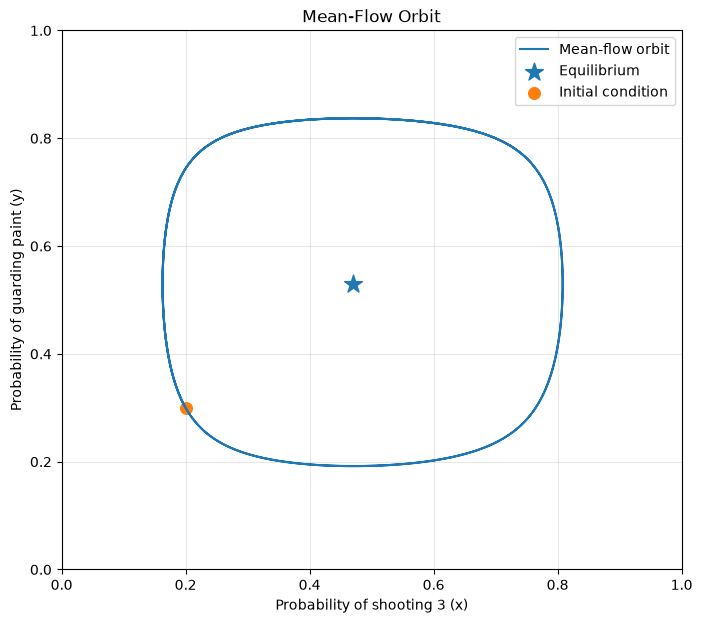

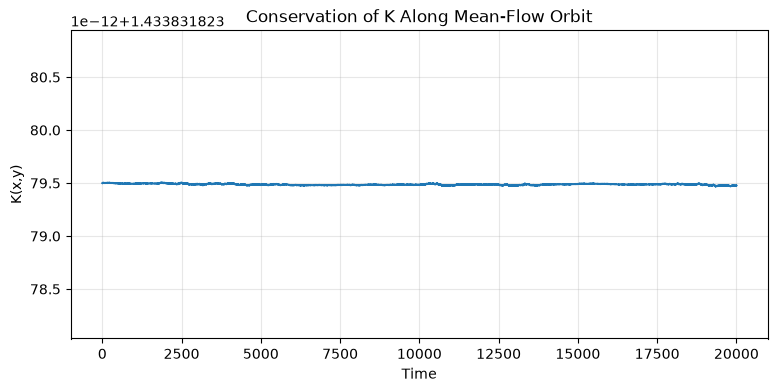

In [26]:
eta = 0.02
x_star = 8/17
y_star = 9/17

# Mean-flow equations
def mean_flow(t, z):
    x, y = z

    dx = 0.85 * eta * (x*(1-x))**2 * (y-y_star)
    dy = -0.85 * eta * (y*(1-y))**2 * (x-x_star)

    return [dx, dy]


# Initial condition
initial = [0.2, 0.3]

# Integrate mean-flow trajectory
solution = solve_ivp(
    mean_flow,
    [0, 20000],
    initial,
    max_step=1,
    rtol=1e-9,
    atol=1e-11
)

x = solution.y[0]
y = solution.y[1]


# Calculate K using an analytical antiderivative
def primitive(s, a):

    return (
        (1-2*a)*np.log(s)
        + (2*a-1)*np.log(1-s)
        + (-a+s*(2*a-1))/(s*(s-1))
    )


def K(x, y):

    Kx = primitive(x, x_star) - primitive(x_star, x_star)
    Ky = primitive(y, y_star) - primitive(y_star, y_star)

    return Kx + Ky


K_values = K(x, y)


# Report results
print("Mean-flow orbit results")

print(f"x range: {x.min():.6f} to {x.max():.6f}")
print(f"y range: {y.min():.6f} to {y.max():.6f}")

print(f"K initial: {K_values[0]:.10f}")
print(f"K final:   {K_values[-1]:.10f}")

print(f"K minimum: {K_values.min():.10f}")
print(f"K maximum: {K_values.max():.10f}")

print(f"K variation: {np.ptp(K_values):.3e}")


# Plot mean-flow orbit
plt.figure(figsize=(8, 7))

plt.plot(x, y, label="Mean-flow orbit")

plt.scatter(
    x_star, y_star,
    marker="*",
    s=180,
    label="Equilibrium"
)

plt.scatter(
    initial[0], initial[1],
    marker="o",
    s=70,
    label="Initial condition"
)

plt.xlabel("Probability of shooting 3 (x)")
plt.ylabel("Probability of guarding paint (y)")
plt.title("Mean-Flow Orbit")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Plot variation in K
plt.figure(figsize=(9, 4))

plt.plot(solution.t, K_values)

plt.xlabel("Time")
plt.ylabel("K(x,y)")
plt.title("Conservation of K Along Mean-Flow Orbit")

plt.grid(alpha=0.3)
plt.show()

In [28]:
N = 400000
eta = 0.02

x_star = 8/17
y_star = 9/17

In [30]:
def sigmoid(theta):
    return 1 / (1 + np.exp(-theta))


def simulate(tau, seed=42):

    rng = np.random.default_rng(seed)

    # Initial logits
    theta1 = 0.3
    theta2 = -0.3

    # Running-average reward baselines
    b1 = 0.0
    b2 = 0.0

    # Store action probabilities
    xs = np.zeros(N)
    ys = np.zeros(N)

    # Store running reward sums
    total_r1 = 0.0
    total_r2 = 0.0

    for t in range(N):

        # Current action probabilities
        x = sigmoid(theta1)
        y = sigmoid(theta2)

        # Sample actions
        a = int(rng.random() < x)  # 1 = shoot 3
        d = int(rng.random() < y)  # 1 = guard paint

        # Probability of making the shot
        if a == 0 and d == 1:
            p_make = 0.40
        elif a == 0 and d == 0:
            p_make = 0.60
        elif a == 1 and d == 1:
            p_make = 0.40
        else:
            p_make = 0.25

        # Random shot outcome
        made = int(rng.random() < p_make)

        # Rewards
        points = (2 + a) * made

        r1 = points
        r2 = -points

        # Store probabilities before updating
        xs[t] = x
        ys[t] = y

        # Policy-gradient updates
        delta1 = (
            (r1-b1)*(a-x)
            - tau*theta1*x*(1-x)
        )

        delta2 = (
            (r2-b2)*(d-y)
            - tau*theta2*y*(1-y)
        )

        theta1 += eta*delta1
        theta2 += eta*delta2

        # Update running-average baselines
        total_r1 += r1
        total_r2 += r2

        b1 = total_r1/(t+1)
        b2 = total_r2/(t+1)

    return xs, ys


# Run simulations
results = {}

for tau in [0, 0.05]:

    xs, ys = simulate(tau, seed=42)

    results[tau] = (xs, ys)

    print(f"Simulation completed: tau = {tau}")


Simulation completed: tau = 0
Simulation completed: tau = 0.05


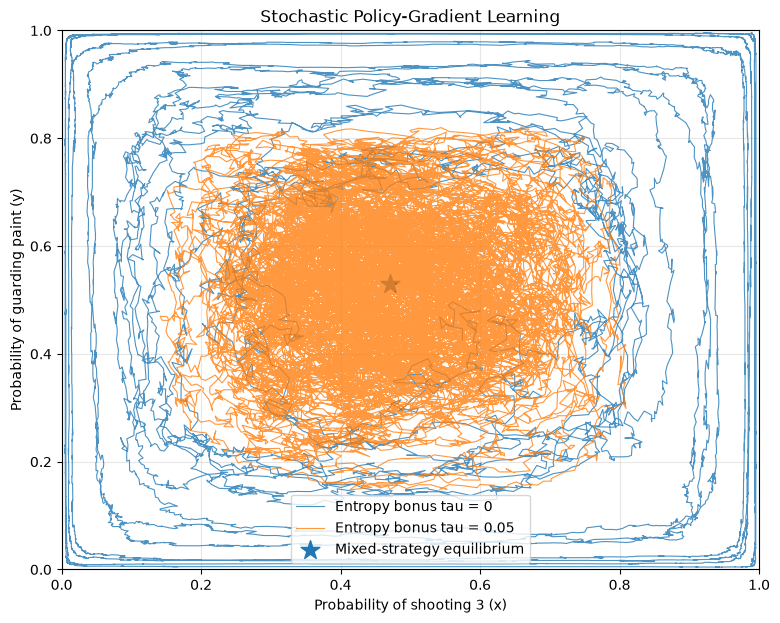

In [31]:
plt.figure(figsize=(9, 7))

for tau in [0, 0.05]:

    xs, ys = results[tau]

    # Downsample to make plotting faster
    step = 20

    plt.plot(
        xs[::step],
        ys[::step],
        linewidth=0.8,
        alpha=0.8,
        label=f"Entropy bonus tau = {tau}"
    )

# Mark equilibrium
plt.scatter(
    x_star, y_star,
    marker="*",
    s=200,
    label="Mixed-strategy equilibrium"
)

plt.xlabel("Probability of shooting 3 (x)")
plt.ylabel("Probability of guarding paint (y)")

plt.title("Stochastic Policy-Gradient Learning")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [34]:
def analyze_simulation(xs, ys):

    # Calculate distance from equilibrium
    distance = np.sqrt(
        (xs-x_star)**2 +
        (ys-y_star)**2
    )

    # Divide simulation into quarters
    quarter = N // 4

    early_distance = np.mean(
        distance[:quarter]
    )

    late_distance = np.mean(
        distance[3*quarter:]
    )

    # Last-quarter averages
    late_x = np.mean(
        xs[3*quarter:]
    )

    late_y = np.mean(
        ys[3*quarter:]
    )

    return late_x, late_y, early_distance, late_distance


# Print comparison
print("SIMULATION RESULTS")
print("-" * 65)

for tau in [0, 0.05]:

    xs, ys = results[tau]

    late_x, late_y, early_dist, late_dist = (
        analyze_simulation(xs, ys)
    )

    print(f"\nEntropy bonus tau = {tau}")

    print(f"Last-quarter average x: {late_x:.5f}")
    print(f"Last-quarter average y: {late_y:.5f}")

    print(f"Early mean distance: {early_dist:.5f}")
    print(f"Late mean distance:  {late_dist:.5f}")

SIMULATION RESULTS
-----------------------------------------------------------------

Entropy bonus tau = 0
Last-quarter average x: 0.51889
Last-quarter average y: 0.46700
Early mean distance: 0.40410
Late mean distance:  0.66982

Entropy bonus tau = 0.05
Last-quarter average x: 0.45442
Last-quarter average y: 0.51818
Early mean distance: 0.19169
Late mean distance:  0.15455
